[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/pantrok/hidroxai-mx/blob/main/notebooks/tutoriales/01_cargar_dataset.ipynb)

# Tutorial 1 · Cargar el dataset Hidro-MX

**Objetivo.** abrir el ZIP público de Zenodo, conocer su estructura, leer la serie diaria de una estación, interpretar las banderas de calidad 0/1/2 y ubicar las estaciones por unidad.

*Proyecto IND-2026-0335 · Instituto Politécnico Nacional (IPN) · Convocatoria PICDT2026. Datos: CONAGUA (Sistema de Información Hidrológica), INEGI y HydroSHEDS.*

In [1]:
# En Colab instala la biblioteca desde GitHub; fuera de Colab usa la que ya esté instalada.
# Va sin dependencias porque Colab ya trae pandas, pyarrow, matplotlib.
import importlib.util
import subprocess
import sys

if "google.colab" in sys.modules and importlib.util.find_spec("hidroxai_mx") is None:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "--no-deps",
                    "git+https://github.com/pantrok/hidroxai-mx@main"], check=True)

## 1. Abrir el ZIP de Zenodo

`abrir_dataset()` abre la versión vigente (v2026.11) directamente en Zenodo. El archivo pesa unos 880 MB, pero no se descarga completo: Zenodo atiende peticiones por rango y solo se bajan los archivos que se leen. Cada archivo leído queda en una caché local (`~/.cache/hidroxai_mx`), así que la segunda lectura es inmediata.

In [2]:
import matplotlib.pyplot as plt
import numpy as np

from hidroxai_mx import report
from hidroxai_mx.dataset import abrir_dataset, como_citar, doi

ds = abrir_dataset()
print(f"Hidro-MX {ds.version} · DOI {doi(ds.version)}")

Hidro-MX v2026.11 · DOI 10.5281/zenodo.24119292


In [3]:
m = ds.miembros()
m["carpeta"] = m["archivo"].str.split("/").str[0]
(m.groupby("carpeta").agg(archivos=("archivo", "size"), mb=("mb", "sum"))
  .sort_values("mb", ascending=False).round(1))

,archivos,mb
carpeta,,
raw,3215,2039.3
processed,279,1044.2
features,1,113.6
results,69,9.2
manifest_zenodo.json,1,0.7
scripts,30,0.3
src,15,0.0
conf,2,0.0
tests,5,0.0


El ZIP trae los datos y todo lo necesario para regenerarlos:

- `raw/`: descargas originales del SIH (CONAGUA) e INEGI, con su manifiesto de procedencia;
- `processed/`: series diarias canónicas en Parquet, particionadas por año, catálogos de estaciones, vínculo con HydroRIVERS y reportes;
- `features/`: tabla diaria de características (gasto, rezagos, medias móviles y precipitación interpolada);
- `src/`, `scripts/`, `conf/` y `tests/`: el código del pipeline; `REPRODUCE.md` explica cómo regenerar cada tabla y figura;
- `results/dib_revision/`: auditorías de la revisión del artículo del dataset.

## 2. Catálogos de estaciones

In [4]:
for conjunto in ("candidatas", "seleccionadas"):
    print(f"Estaciones hidrométricas {conjunto}: {len(ds.estaciones(conjunto=conjunto))}")
print(f"Estaciones climatológicas seleccionadas: {len(ds.estaciones('climatologicas'))}")
est = ds.estaciones()
est.head()

Estaciones hidrométricas candidatas: 550
Estaciones hidrométricas seleccionadas: 101
Estaciones climatológicas seleccionadas: 415


,clave,nombre,latitud,longitud,altitud,estado,municipio,region_hidrologica,cuenca,cobertura,vecinos_clima
0,ACSGJ,"Arroyo los castillos, Gto.",21.200000,-101.666667,1874,Guanajuato,León,12,Medio Lerma,0.702259,"CSTGJ,EPLGJ,LENGJ"
1,AMCGJ,"Ameche, Gto.",20.553889,-100.582500,1786,Guanajuato,Apaseo el Grande,12,La Laja,0.910164,"AMCGJ,AEGGJ,APSGJ"
2,ANSGJ,"Arandas, Gto.",20.712778,-101.370833,1740,Guanajuato,Irapuato,12,Medio Lerma,0.843600,"ECNGJ,IRPGJ,TEMGJ"
3,BEGGJ,"La Begoña hidrométrica, Gto.",20.833333,-100.816667,1820,Guanajuato,San Miguel de Allende,12,La Laja,0.818960,"IALGJ,CSRGJ,PNLGJ"
4,BRAGJ,"Braniff, Gto.",20.050000,-100.666667,1879,Guanajuato,Acámbaro,12,Alto Lerma,0.814682,"SLSGJ,ACNGJ,JCRGJ"


## 3. Serie diaria de una estación

Las series están particionadas por año; `anios` elige las particiones y `claves` filtra las estaciones al leer.

In [5]:
clave = "SLVGJ"
q = ds.series_hidrometricas(claves=[clave], anios=range(2010, 2026))
print(est.loc[est["clave"] == clave, ["clave", "nombre", "estado", "cobertura"]].to_string(index=False))
q.head()

clave            nombre     estado  cobertura
SLVGJ Salvatierra, Gto. Guanajuato   0.916324


,fecha,nivel_m,gasto_medio_m3s,clave_estacion,fuente,calidad,anio
0,2010-01-01,NaN,0.0,SLVGJ,SIH,1,2010
1,2010-01-02,NaN,0.0,SLVGJ,SIH,1,2010
2,2010-01-03,NaN,0.0,SLVGJ,SIH,1,2010
3,2010-01-04,NaN,0.0,SLVGJ,SIH,1,2010
4,2010-01-05,2.0,0.0,SLVGJ,SIH,0,2010


## 4. Banderas de calidad

Cada valor lleva una bandera `calidad`:

- **0**: valor original del SIH;
- **1**: hueco interno de 1 a 6 días rellenado por interpolación lineal (los huecos de 7 días o más se dejan vacíos);
- **2**: valor marcado, negativo o mayor que 3 veces el percentil 99.9 de la estación. Se conserva: algunos son crecidas reales.

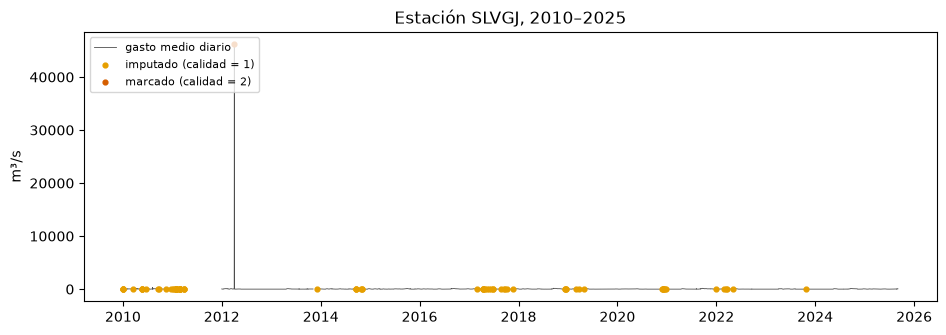

In [6]:
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(q["fecha"], q["gasto_medio_m3s"], lw=0.6, color="0.3", label="gasto medio diario")
for cal, color, etiqueta in [(1, "#E69F00", "imputado (calidad = 1)"),
                             (2, "#D55E00", "marcado (calidad = 2)")]:
    s = q[q["calidad"] == cal]
    ax.scatter(s["fecha"], s["gasto_medio_m3s"], s=12, color=color, label=etiqueta, zorder=3)
ax.set_ylabel("m³/s")
ax.set_title(f"Estación {clave}, 2010–2025")
ax.legend(loc="upper left", fontsize=8)
plt.show()

Proporción de cada bandera en las estaciones seleccionadas, 2010–2025 (solo días con valor):

In [7]:
sel = ds.series_hidrometricas(claves=est["clave"], anios=range(2010, 2026),
                              columnas=["clave_estacion", "fecha", "gasto_medio_m3s", "calidad"])
banderas = report.quality_summary(sel, "gasto_medio_m3s")
banderas["etiqueta"] = banderas["calidad"].map({0: "original", 1: "imputado", 2: "marcado"})
banderas.round(2)

,calidad,etiqueta,n,pct
0,0,original,447946,92.49
1,1,imputado,36305,7.50
2,2,marcado,59,0.01


## 5. Estaciones por unidad

Las unidades piloto del dataset son recortes geográficos de `conf/cuencas_piloto.yaml`; cada estación seleccionada se asigna a una unidad en `processed/estaciones_hidrorivers.csv`, junto con su tramo de HydroRIVERS v1.0.

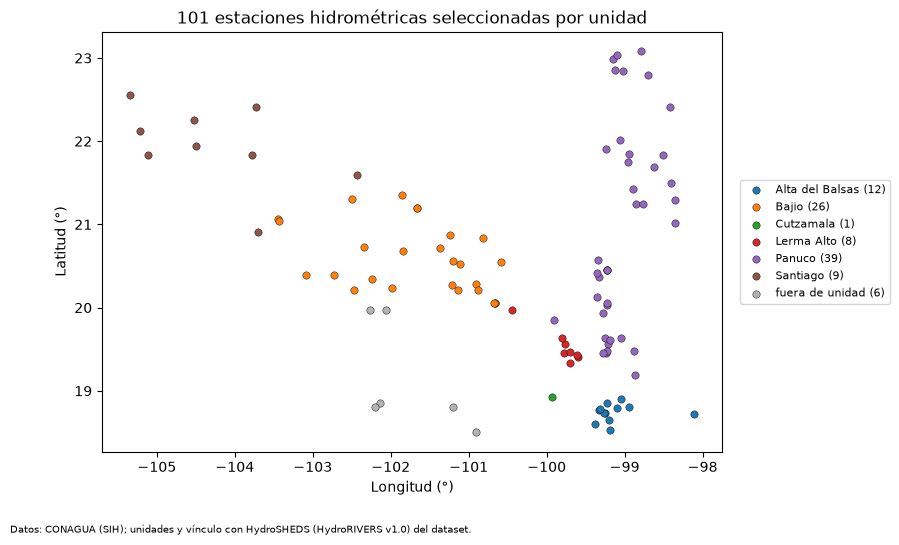

In [8]:
vinc = ds.vinculo_hidrorivers()
mapa = est.merge(vinc[["clave", "unidad_piloto"]], on="clave", how="left")
mapa["unidad_piloto"] = mapa["unidad_piloto"].fillna("fuera de unidad")
fig, ax = plt.subplots(figsize=(8, 6))
for unidad, g in mapa.groupby("unidad_piloto"):
    color = "0.7" if unidad == "fuera de unidad" else None
    ax.scatter(g["longitud"], g["latitud"], s=28, color=color, edgecolor="k", lw=0.3,
               label=f"{unidad} ({len(g)})")
ax.set_aspect(1 / np.cos(np.radians(mapa["latitud"].mean())))
ax.set_xlabel("Longitud (°)")
ax.set_ylabel("Latitud (°)")
ax.set_title(f"{len(mapa)} estaciones hidrométricas seleccionadas por unidad")
ax.legend(fontsize=8, loc="center left", bbox_to_anchor=(1.02, 0.5))
fig.text(0.01, 0.01, "Datos: CONAGUA (SIH); unidades y vínculo con HydroSHEDS (HydroRIVERS v1.0) del dataset.",
         fontsize=7)
plt.show()

## Cómo citar

Si usas estos datos, cita el artículo que describe el dataset (*Data in Brief*, 2026) y la versión del dataset que usaste. Las referencias salen de los metadatos de Crossref y de Zenodo.

In [9]:
print(como_citar())

Artículo de datos:
Sánchez-Ruiz, D., Reyes-Peña, C., Reyes-Cocoletzi, L., García-Ramírez, J., Ramos-Aguilar, E., & Ramos-Aguilar, R. (2026). Hidro-MX: daily hydroclimatic dataset for four pilot basins in Mexico from National Water Commission and National Institute of Statistics and Geography sources, with digital elevation models and station–river network links. Data in Brief, 69, 113442. https://doi.org/10.1016/j.dib.2026.113442

Dataset (v2026.11):
Sánchez-Ruiz, D., Ramos Aguilar, E., Ramos-Aguilar, R., Reyes-Peña, C., Reyes-Cocoletzi, L., & García-Ramírez, J. (2026). Hidro-MX v2026.11: a reproducible hydroclimatic dataset for Mexican pilot basins (CONAGUA-SIH and INEGI) [Data set]. Zenodo. https://doi.org/10.5281/zenodo.24119292
Todas las versiones (DOI de concepto): https://doi.org/10.5281/zenodo.21231600

Créditos: Instituto Politécnico Nacional (IPN) · Convocatoria PICDT2026 · proyecto IND-2026-0335. Datos: CONAGUA (Sistema de Información Hidrológica), INEGI y HydroSHEDS.
